In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [39]:
df = pd.read_parquet("4FLG_Procesado.parquet")
df

,CLASS1,BlazarDist,Variability_Index,Frac_Variability,SpectrumType_LogParabola,SpectrumType_PowerLaw,SpectrumType_PLSuperExpCutoff,Energy_Flux100,LP_Index,LP_SigCurv,PL_Index,Pivot_Energy,Flux_Band_0,Flux_Band_4,Flux_Band_6,Flux_Band_7,nuFnu_Band_0,nuFnu_Band_4,nuFnu_Band_6,nuFnu_Band_7
0,bll,blazar,51.742390,0.429135,0,1,0,7.807578e-12,2.052470,1.283201,2.081634,2065.146729,1.664147e-12,1.866136e-10,1.364606e-11,1.204809e-12,2.657329e-16,1.268975e-12,9.279336e-13,2.075041e-13
1,bcu,blazar,25.609457,0.368921,1,0,0,3.260804e-12,1.580971,2.630329,1.781085,2729.530029,1.858900e-10,9.661182e-11,1.290118e-11,1.572634e-12,3.136423e-14,6.833589e-13,8.547137e-13,2.149872e-13
2,bcu,blazar,26.910145,0.937606,0,1,0,8.967048e-13,1.763400,0.958782,1.906426,4281.748047,3.287979e-11,2.881598e-11,4.228593e-16,1.748820e-12,5.286959e-15,2.000432e-13,2.935529e-17,3.234954e-13
3,bll,blazar,10.370596,0.000000,1,0,0,2.441939e-12,1.599259,3.092949,1.817964,3402.819092,4.485441e-09,6.530654e-11,5.156945e-12,4.613763e-17,7.668804e-13,4.618040e-13,3.346412e-13,5.758958e-18
4,other,non-blazar,7.720544,0.000000,1,0,0,4.373159e-12,2.641635,3.182654,2.518880,1996.203979,9.472302e-14,6.726024e-11,3.627743e-16,1.618911e-16,1.578786e-17,4.073829e-13,1.990180e-17,1.499963e-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2912,bcu,blazar,18.010399,0.259739,1,0,0,1.354165e-12,1.577917,3.787348,1.752499,5153.450684,6.129970e-12,4.413272e-11,1.857165e-12,5.640288e-17,1.062581e-15,3.169375e-13,1.105479e-13,5.420474e-18
2913,bll,blazar,14.498226,0.068273,0,1,0,4.093997e-12,1.924309,0.000000,1.928476,2930.842285,4.975796e-09,8.682364e-11,1.378831e-11,1.948438e-12,7.993894e-13,6.011633e-13,9.546973e-13,3.571405e-13
2914,bcu,blazar,6.934350,0.000000,1,0,0,1.116031e-12,2.639918,3.037318,2.714450,717.048584,2.112895e-08,4.710498e-12,8.963529e-15,3.741380e-15,3.582740e-12,2.547993e-14,4.679423e-16,3.466486e-16
2915,bcu,blazar,8.082824,0.000000,1,0,0,1.752340e-12,1.904424,2.774415,2.094933,1490.850708,8.510176e-14,6.003090e-11,1.787903e-12,1.558835e-19,1.431744e-17,3.939935e-13,1.071259e-13,1.637076e-20


In [40]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score
from sklearn.preprocessing import StandardScaler


In [41]:
#Preparación y escalamiento de datos para el modelo de clasificación
from imblearn.over_sampling import SMOTE

smote = True

X_blazar = df.drop(columns=["CLASS1", "BlazarDist"])
y_blazar = df["BlazarDist"]
y_class = df["CLASS1"]

print("Numero de muestras por clase antes de aplicar SMOTE:")
print(y_blazar.value_counts())

sm = SMOTE(random_state=42)
if smote:
    X_blazar, y_blazar= sm.fit_resample(X_blazar, y_blazar)

print("Numero de muestras por clase después de aplicar SMOTE:")
print(y_blazar.value_counts())

X_train, X_test, y_train, y_test = train_test_split(X_blazar, y_blazar, test_size=0.2, random_state=42, stratify=y_blazar)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Numero de muestras por clase antes de aplicar SMOTE:
BlazarDist
blazar        2257
non-blazar     660
Name: count, dtype: int64
Numero de muestras por clase después de aplicar SMOTE:
BlazarDist
blazar        2257
non-blazar    2257
Name: count, dtype: int64


In [42]:
#Entrenar y evaluar modelo

classifier = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

              precision    recall  f1-score   support

      blazar       0.89      0.94      0.91       452
  non-blazar       0.94      0.88      0.91       451

    accuracy                           0.91       903
   macro avg       0.91      0.91      0.91       903
weighted avg       0.91      0.91      0.91       903

ROC AUC: 0.9634587838235583
Confussion Matrix:


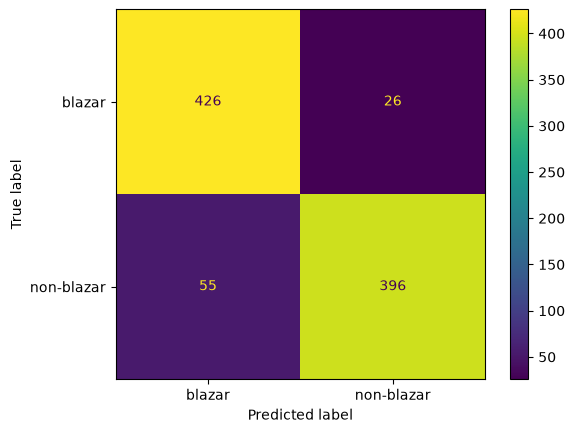

In [43]:
print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, classifier.predict_proba(X_test)[:,1]))

print("Confussion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=classifier.classes_)
disp.plot()

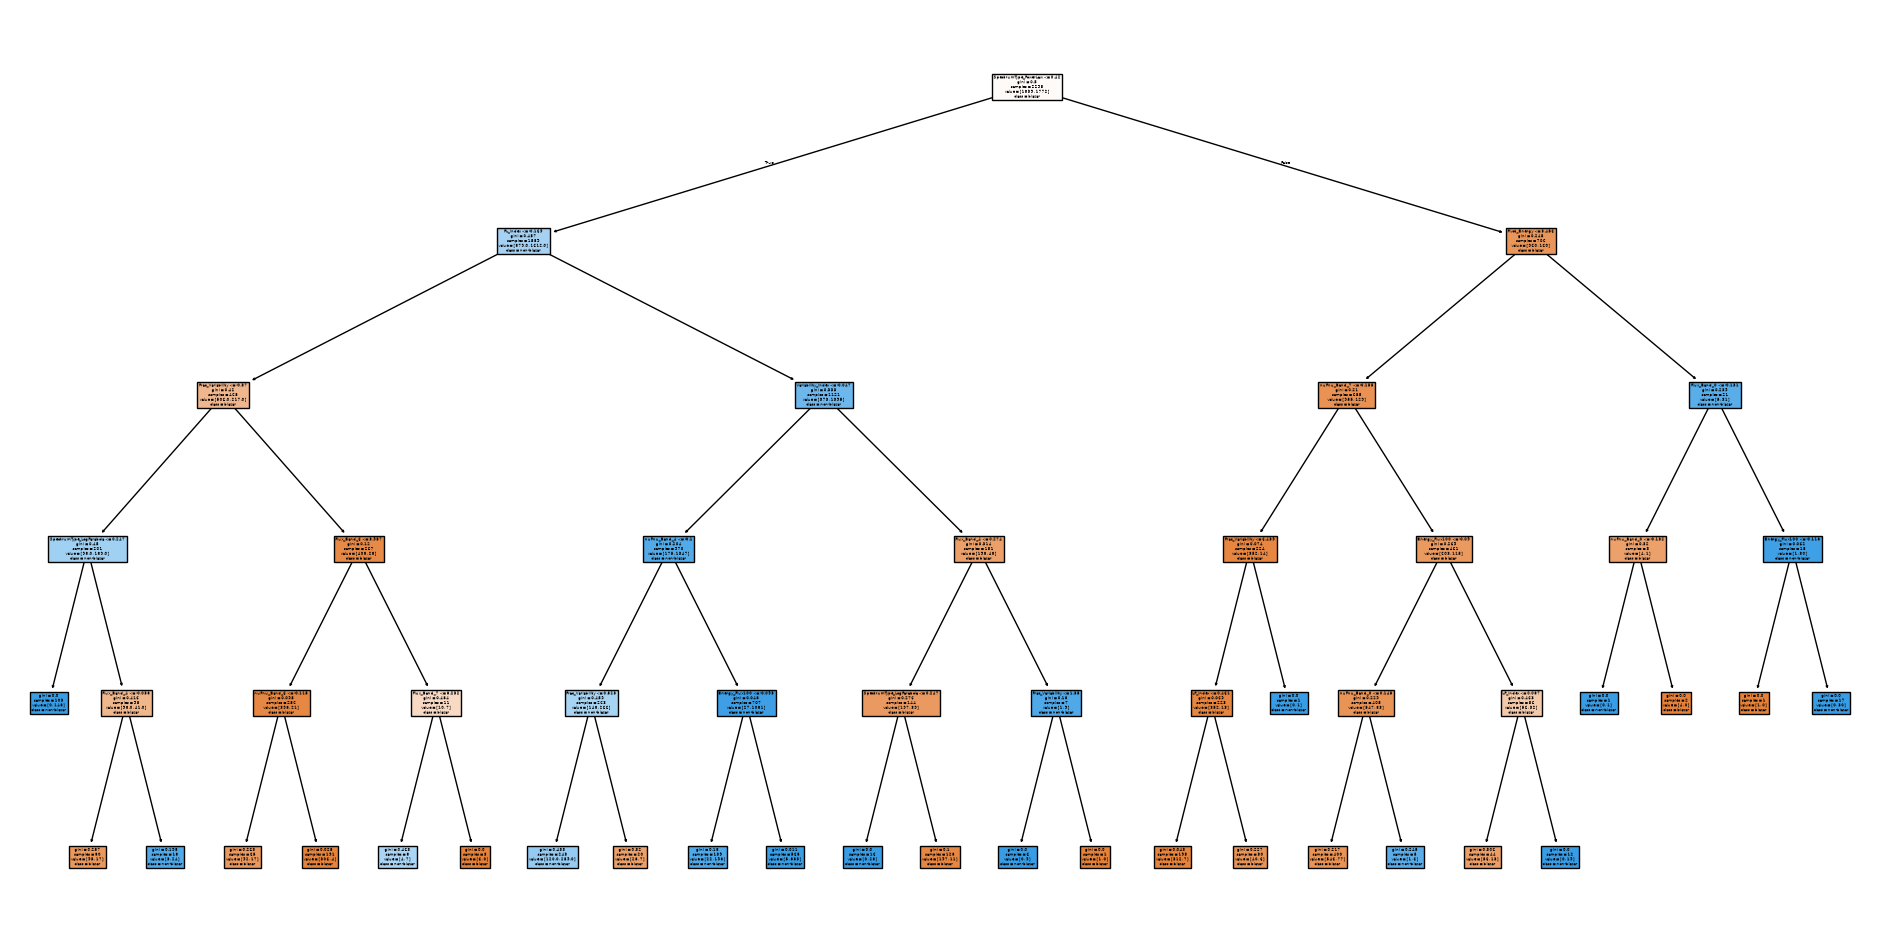

In [44]:
from sklearn.tree import plot_tree

tree = classifier.estimators_[0]
plt.figure(figsize=(24,12))
plot_tree(tree, feature_names=X_blazar.columns, class_names=classifier.classes_, filled=True)
plt.savefig("mi_arbol_binary.png", bbox_inches="tight", dpi=300)

C:\Users\Administrador\AppData\Local\Temp\ipykernel_22064\593920716.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


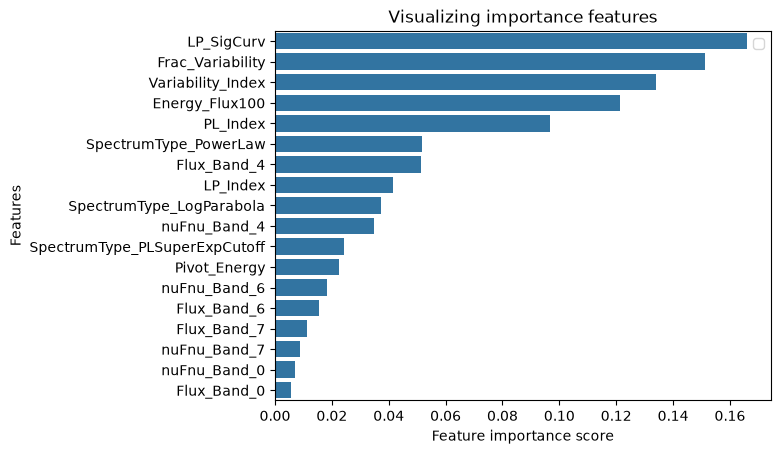

In [45]:
feature_imp = pd.Series(classifier.feature_importances_,index=X_blazar.columns).sort_values(ascending=False)

sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Feature importance score')
plt.ylabel('Features')
plt.title("Visualizing importance features")
plt.legend()
plt.show()

#Clasificación de tipos

In [46]:
smote = False

X_class = df.drop(columns=["CLASS1", "BlazarDist"])
y_class = df["CLASS1"]

X_blazar = df.drop(columns=["CLASS1", "BlazarDist"])
y_blazar = df["BlazarDist"]
y_class = df["CLASS1"]


print("Class distribution before SMOTE:")
print(y_class.value_counts())

sm = SMOTE(random_state=42)
if smote:
    X_class, y_class= sm.fit_resample(X_class, y_class)

print("Class distribution after SMOTE:")
print(y_class.value_counts())

X_train, X_test, y_train, y_test = train_test_split(X_class, y_class, test_size=0.2, random_state=42, stratify=y_class)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Class distribution before SMOTE:
CLASS1
bll      1092
bcu       947
other     660
fsrq      218
Name: count, dtype: int64
Class distribution after SMOTE:
CLASS1
bll      1092
bcu       947
other     660
fsrq      218
Name: count, dtype: int64


In [47]:
#Entrenar y evaluar modelo

classifier = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

              precision    recall  f1-score   support

         bcu       0.52      0.62      0.56       189
         bll       0.71      0.74      0.73       219
        fsrq       0.67      0.32      0.43        44
       other       0.87      0.72      0.79       132

    accuracy                           0.66       584
   macro avg       0.69      0.60      0.63       584
weighted avg       0.68      0.66      0.67       584

Confussion Matrix:


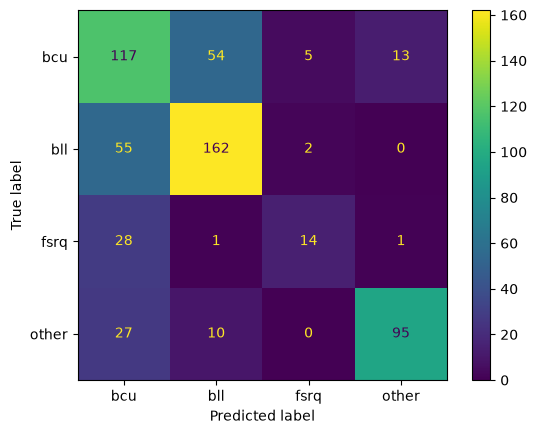

In [48]:
print(classification_report(y_test, y_pred))

print("Confussion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=classifier.classes_)
disp.plot()

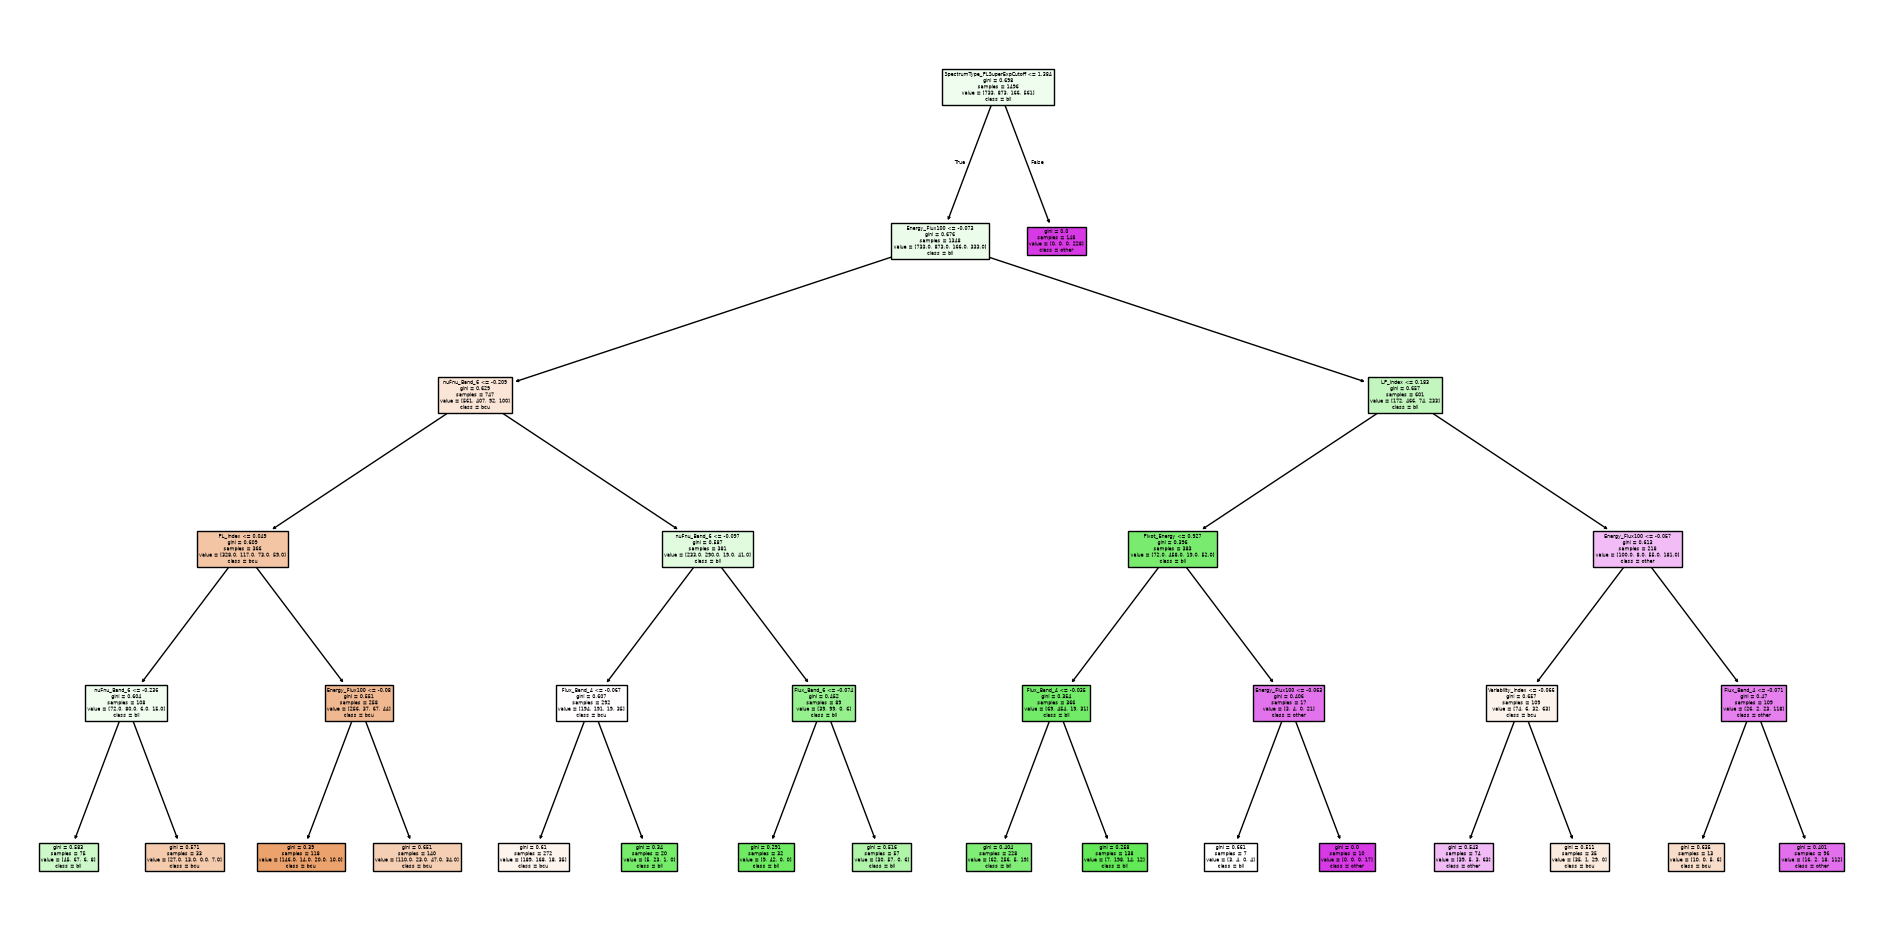

In [49]:
from sklearn.tree import plot_tree

tree = classifier.estimators_[0]
plt.figure(figsize=(24,12))
plot_tree(tree, feature_names=X_class.columns, class_names=classifier.classes_, filled=True)
plt.savefig("mi_arbol_multiclass.png", bbox_inches="tight", dpi=300)